<a href="https://colab.research.google.com/github/Nurfinkaa/MachineLearning/blob/main/js9/TG9_TG_2_244107020211_NURFINKA_LAILASARI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Tugas 2 - Klasifikasi SMS Spam dengan Multinomial Naive Bayes**

## 0.1 Upload dataset

In [ ]:
from google.colab import files
uploaded = files.upload()   # pilih file spam.csv

Saving spam.csv to spam (1).csv


## 0.2 Import library

In [ ]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

## 1. Load dan Pra Pengolahan Data
`spam.csv` memakai encoding `latin-1`. Kolom hasil: `v1` (label), `v2` (teks SMS), dan 3 kolom `Unnamed` yang tidak berguna.

In [ ]:
csv_path = sorted(glob.glob('spam*.csv'))[0]   # otomatis ambil file spam*.csv yang diupload
print('Membaca file:', csv_path)
df = pd.read_csv(csv_path, encoding='latin-1')
df.head()

Membaca file: spam (1).csv


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


### 1a. Buang kolom tidak terpakai dan ubah nama kolom

In [ ]:
df = df[['v1', 'v2']]            # hanya ambil label dan teks
df.columns = ['Labels', 'SMS']   # v1 -> Labels, v2 -> SMS
df.head()

,Labels,SMS
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### 1b. Inspeksi data

In [ ]:
print(df['Labels'].value_counts())
print()
print(df.info())
print()
print(df.isnull().sum())

Labels
ham     4825
spam     747
Name: count, dtype: int64

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Labels  5572 non-null   object
 1   SMS     5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None

Labels    0
SMS       0
dtype: int64


Data **tidak seimbang** (ham jauh lebih banyak daripada spam). Karena itu, selain akurasi, evaluasi juga memakai precision, recall, dan F1-score untuk kelas spam.

### 1c. Encoding label (spam = 1, ham = 0) dan pisahkan fitur-label

In [ ]:
df['Labels'] = df['Labels'].map({'spam': 1, 'ham': 0})

X = df['SMS'].values
y = df['Labels'].values
print(X.shape, y.shape)

(5572,) (5572,)


### 1d. Split data training dan testing (80:20)
Split dilakukan **sebelum** ekstraksi fitur untuk mencegah *leaking information*. Split yang sama dipakai untuk kedua fitur supaya perbandingannya adil.

In [ ]:
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=50)

print('Training:', len(X_train_txt), '| Testing:', len(X_test_txt))
print('Proporsi spam training:', y_train.mean().round(4), '| testing:', y_test.mean().round(4))

Training: 4457 | Testing: 1115
Proporsi spam training: 0.1315 | testing: 0.1444


# Bagian 1 - Multinomial Naive Bayes + CountVectorizer (stop_words aktif)

## 2.1 Ekstraksi fitur Bag of Words

In [ ]:
bow = CountVectorizer(stop_words='english')   # stop_words diaktifkan

X_train_bow = bow.fit_transform(X_train_txt)   # fit hanya pada data training
X_test_bow = bow.transform(X_test_txt)         # test hanya di-transform

print('Jumlah fitur (kata unik):', len(bow.get_feature_names_out()))
print('Dimensi data training   :', X_train_bow.shape)
print('Dimensi data testing    :', X_test_bow.shape)

Jumlah fitur (kata unik): 7466
Dimensi data training   : (4457, 7466)
Dimensi data testing    : (1115, 7466)


## 2.2 Training dan evaluasi model

In [ ]:
mnb_bow = MultinomialNB()
mnb_bow.fit(X_train_bow, y_train)

ytr_pred_bow = mnb_bow.predict(X_train_bow)
yte_pred_bow = mnb_bow.predict(X_test_bow)

acc_train_bow = accuracy_score(y_train, ytr_pred_bow)
acc_test_bow = accuracy_score(y_test, yte_pred_bow)

print(f'Akurasi data train: {acc_train_bow:.4f}')
print(f'Akurasi data test : {acc_test_bow:.4f}')

Akurasi data train: 0.9946
Akurasi data test : 0.9830


Confusion Matrix (CountVectorizer):
[[951   3]
 [ 16 145]]

              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       954
        spam       0.98      0.90      0.94       161

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



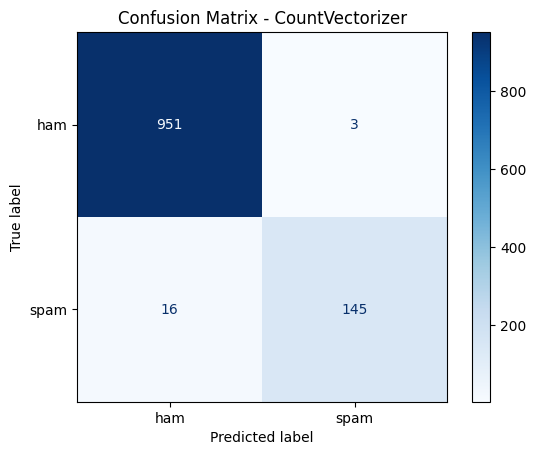

In [ ]:
print('Confusion Matrix (CountVectorizer):')
print(confusion_matrix(y_test, yte_pred_bow))
print()
print(classification_report(y_test, yte_pred_bow, target_names=['ham', 'spam']))

ConfusionMatrixDisplay.from_predictions(
    y_test, yte_pred_bow, display_labels=['ham', 'spam'], cmap='Blues')
plt.title('Confusion Matrix - CountVectorizer')
plt.show()

# Bagian 2 - Multinomial Naive Bayes + TF-IDF (stop_words aktif)

## 3.1 Ekstraksi fitur TF-IDF

In [ ]:
tfidf = TfidfVectorizer(stop_words='english')   # stop_words diaktifkan

X_train_tfidf = tfidf.fit_transform(X_train_txt)   # fit hanya pada data training
X_test_tfidf = tfidf.transform(X_test_txt)

print('Jumlah fitur (kata unik):', len(tfidf.get_feature_names_out()))
print('Dimensi data training   :', X_train_tfidf.shape)
print('Dimensi data testing    :', X_test_tfidf.shape)

Jumlah fitur (kata unik): 7466
Dimensi data training   : (4457, 7466)
Dimensi data testing    : (1115, 7466)


## 3.2 Training dan evaluasi model

In [ ]:
mnb_tfidf = MultinomialNB()
mnb_tfidf.fit(X_train_tfidf, y_train)

ytr_pred_tfidf = mnb_tfidf.predict(X_train_tfidf)
yte_pred_tfidf = mnb_tfidf.predict(X_test_tfidf)

acc_train_tfidf = accuracy_score(y_train, ytr_pred_tfidf)
acc_test_tfidf = accuracy_score(y_test, yte_pred_tfidf)

print(f'Akurasi data train: {acc_train_tfidf:.4f}')
print(f'Akurasi data test : {acc_test_tfidf:.4f}')

Akurasi data train: 0.9843
Akurasi data test : 0.9605


Confusion Matrix (TF-IDF):
[[954   0]
 [ 44 117]]

              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       954
        spam       1.00      0.73      0.84       161

    accuracy                           0.96      1115
   macro avg       0.98      0.86      0.91      1115
weighted avg       0.96      0.96      0.96      1115



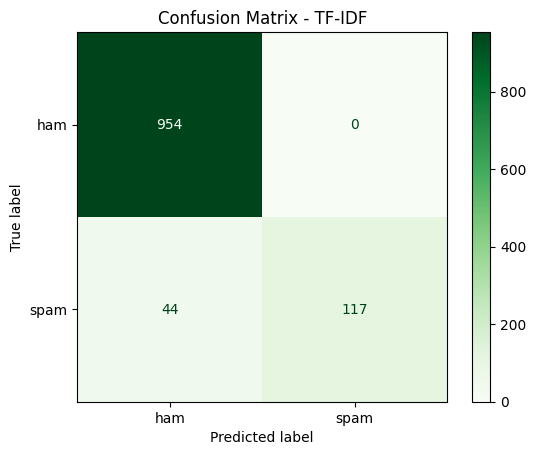

In [ ]:
print('Confusion Matrix (TF-IDF):')
print(confusion_matrix(y_test, yte_pred_tfidf))
print()
print(classification_report(y_test, yte_pred_tfidf, target_names=['ham', 'spam']))

ConfusionMatrixDisplay.from_predictions(
    y_test, yte_pred_tfidf, display_labels=['ham', 'spam'], cmap='Greens')
plt.title('Confusion Matrix - TF-IDF')
plt.show()

# Perbandingan CountVectorizer vs TF-IDF

In [ ]:
def ringkas(nama, ytr, ytr_pred, yte, yte_pred):
    return {
        'Fitur': nama,
        'Akurasi Train': accuracy_score(ytr, ytr_pred),
        'Akurasi Test': accuracy_score(yte, yte_pred),
        'Precision (spam)': precision_score(yte, yte_pred),
        'Recall (spam)': recall_score(yte, yte_pred),
        'F1 (spam)': f1_score(yte, yte_pred),
    }

perbandingan = pd.DataFrame([
    ringkas('CountVectorizer', y_train, ytr_pred_bow, y_test, yte_pred_bow),
    ringkas('TF-IDF', y_train, ytr_pred_tfidf, y_test, yte_pred_tfidf),
]).set_index('Fitur')

perbandingan.round(4)

,Akurasi Train,Akurasi Test,Precision (spam),Recall (spam),F1 (spam)
Fitur,,,,,
CountVectorizer,0.9946,0.9830,0.9797,0.9006,0.9385
TF-IDF,0.9843,0.9605,1.0000,0.7267,0.8417


In [ ]:
# Jumlah kesalahan prediksi pada data testing
for nama, pred in [('CountVectorizer', yte_pred_bow), ('TF-IDF', yte_pred_tfidf)]:
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f'{nama:16s} | ham salah dikira spam (FP): {fp:3d} | spam lolos dikira ham (FN): {fn:3d}')

CountVectorizer  | ham salah dikira spam (FP):   3 | spam lolos dikira ham (FN):  16
TF-IDF           | ham salah dikira spam (FP):   0 | spam lolos dikira ham (FN):  44


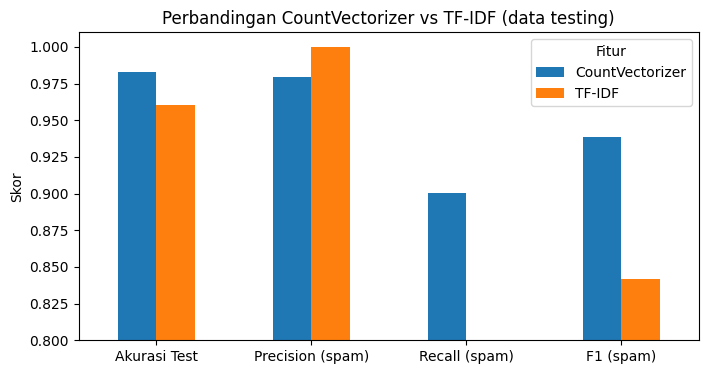

In [ ]:
ax = perbandingan[['Akurasi Test', 'Precision (spam)', 'Recall (spam)', 'F1 (spam)']].T.plot(
    kind='bar', figsize=(8, 4), rot=0)
ax.set_ylabel('Skor')
ax.set_ylim(0.8, 1.01)
ax.set_title('Perbandingan CountVectorizer vs TF-IDF (data testing)')
plt.show()

# Kesimpulan

In [ ]:
skor = perbandingan['F1 (spam)']
akur = perbandingan['Akurasi Test']
terbaik = skor.idxmax()

print('Akurasi test   :', akur.round(4).to_dict())
print('F1-score spam  :', skor.round(4).to_dict())
print()
if skor['CountVectorizer'] == skor['TF-IDF']:
    print('Kedua fitur memberikan F1-score spam yang sama; perbedaan ada pada jenis kesalahan (lihat FP/FN).')
else:
    print(f'Berdasarkan F1-score kelas spam, fitur terbaik pada data spam.csv adalah: {terbaik}')

Akurasi test   : {'CountVectorizer': 0.983, 'TF-IDF': 0.9605}
F1-score spam  : {'CountVectorizer': 0.9385, 'TF-IDF': 0.8417}

Berdasarkan F1-score kelas spam, fitur terbaik pada data spam.csv adalah: CountVectorizer


## **Laoran Hasil Tugas 2: Klasifikasi SMS Spam dengan Multinomial Naive Bayes**



Data `spam.csv` berisi 5572 SMS (ham 4825, spam 747), jadi data **tidak seimbang**. Data dibagi 80:20 (training 4457, testing 1115) sebelum ekstraksi fitur agar tidak terjadi *leaking information*. Karena itu evaluasi tidak hanya memakai akurasi, tetapi juga precision, recall, dan F1-score kelas spam.

### **1. Multinomial Naive Bayes + CountVectorizer (stop_words aktif)**

Jumlah fitur (kata unik) ada 7466. Akurasi data train **99,46%** dan akurasi data test **98,30%**.

| | Prediksi ham | Prediksi spam |
|---|---|---|
| **Aktual ham** | 951 | 3 |
| **Aktual spam** | 16 | 145 |

Untuk kelas spam: precision **0,9797**, recall **0,9006**, F1-score **0,9385**.

Dari 1115 data test, hanya 19 yang salah prediksi: 3 ham dikira spam (FP) dan 16 spam lolos dikira ham (FN).

### **2. Multinomial Naive Bayes + TF-IDF (stop_words aktif)**

Jumlah fitur (kata unik) juga 7466. Akurasi data train **98,43%** dan akurasi data test **96,05%**.

| | Prediksi ham | Prediksi spam |
|---|---|---|
| **Aktual ham** | 954 | 0 |
| **Aktual spam** | 44 | 117 |

Untuk kelas spam: precision **1,0000**, recall **0,7267**, F1-score **0,8417**.

Dari 1115 data test, ada 44 yang salah prediksi: 0 ham dikira spam (FP) dan 44 spam lolos dikira ham (FN).

### **3. Perbandingan CountVectorizer vs TF-IDF (data test)**

| Metrik | CountVectorizer | TF-IDF |
|---|---|---|
| Akurasi | 0,9830 | 0,9605 |
| Precision (spam) | 0,9797 | 1,0000 |
| Recall (spam) | 0,9006 | 0,7267 |
| F1-score (spam) | 0,9385 | 0,8417 |
| FP (ham dikira spam) | 3 | 0 |
| FN (spam lolos) | 16 | 44 |

- **TF-IDF** unggul di precision (1,0000) dan tidak pernah salah memblokir pesan ham. Tetapi recall-nya rendah (0,7267), sehingga 44 SMS spam lolos ke inbox.
- **CountVectorizer** sedikit mengorbankan precision (3 ham salah dikira spam), tetapi recall jauh lebih tinggi (0,9006). Spam yang lolos hanya 16, dan akurasi serta F1-score juga lebih tinggi.
- Dugaan penyebabnya: pada data spam, kemunculan kata-kata khas spam (misalnya "free", "call", "txt") sudah cukup informatif apabila dihitung sebagai frekuensi. Pembobotan TF-IDF menurunkan bobot kata yang sering muncul, sehingga kata-kata penciri spam ini kurang berpengaruh dan model lebih cenderung memprediksi ham. Ini hanya penjelasan yang masuk akal, tidak diuji langsung di notebook.

### **4.  Kesimpulan**

Fitur terbaik pada data `spam.csv` adalah **CountVectorizer**. Pada data testing, CountVectorizer menghasilkan akurasi **98,30%** (TF-IDF 96,05%) dan F1-score kelas spam **0,9385** (TF-IDF 0,8417). Karena data tidak seimbang, F1-score kelas spam dijadikan dasar utama, dan CountVectorizer jauh lebih seimbang antara precision dan recall.